# Phase 6: High-Cardinality Category Reduction & Rare Grouping

This notebook implements supervised frequency-threshold category reduction on the training dataset (`X_train`) for the identified high-cardinality feature (`OCCP`).

### Protocol Requirements:
1. Minimum frequency threshold: **100 training observations**.
2. Categories with $\ge 100$ counts are preserved; categories with $< 100$ counts are mapped to `"Rare"`.
3. Export mapping dictionary to `results/06_category_mapping.json`.
4. Create new column `OCCP_grouped` without modifying the original `OCCP` column.
5. Export enriched feature matrix to `data/processed/X_train_grouped.csv`.
6. Compute reduction summary metrics (`results/06_cardinality_reduction_summary.csv`).
7. Visualize category distributions before and after grouping.
8. Enforce leakage prevention: mapping learned strictly on `X_train`.


In [1]:
import os
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# Resolve paths dynamically
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name in ['notebooks', 'src'] else NOTEBOOK_DIR

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

X_TRAIN_PATH = DATA_PROCESSED_DIR / "X_train.csv"
SELECTED_FEATURE_PATH = RESULTS_DIR / "04_selected_high_cardinality_feature.txt"

print(f"Project root: {PROJECT_ROOT}")
print(f"X_train path: {X_TRAIN_PATH} (Exists: {X_TRAIN_PATH.exists()})")
print(f"Feature file: {SELECTED_FEATURE_PATH} (Exists: {SELECTED_FEATURE_PATH.exists()})")


Project root: D:\Github Repo\C-Square
X_train path: D:\Github Repo\C-Square\data\processed\X_train.csv (Exists: True)
Feature file: D:\Github Repo\C-Square\results\04_selected_high_cardinality_feature.txt (Exists: True)


In [2]:
# Task 1 & 2: Load training data and retrieve high-cardinality feature name
X_train = pd.read_csv(X_TRAIN_PATH)

with open(SELECTED_FEATURE_PATH, "r", encoding="utf-8") as f:
    feature_name = f.read().strip()

print("=" * 70)
print(f"HIGH-CARDINALITY FEATURE TO REDUCE: {feature_name}")
print(f"Total training observations:        {len(X_train):,}")
print("=" * 70)


HIGH-CARDINALITY FEATURE TO REDUCE: OCCP
Total training observations:        154,204


In [3]:
# Task 1, 2, 3: Build mapping dictionary using threshold = 100 observations
THRESHOLD = 100
vc_orig = X_train[feature_name].value_counts()
n_original_categories = len(vc_orig)

# Mapping: original category -> original category (if >= 100) else "Rare"
category_mapping = {}
for cat, count in vc_orig.items():
    category_mapping[str(cat)] = str(cat) if count >= THRESHOLD else "Rare"

n_rare_categories = sum(1 for v in category_mapping.values() if v == "Rare")
n_kept_categories = n_original_categories - n_rare_categories

print("=" * 70)
print(f"MAPPING GENERATION (THRESHOLD = {THRESHOLD}):")
print("=" * 70)
print(f"Original categories count:           {n_original_categories}")
print(f"Categories meeting threshold (>=100): {n_kept_categories}")
print(f"Categories grouped into 'Rare':      {n_rare_categories}")
print(f"Sample mapping entries (first 5):")
for k in list(category_mapping.keys())[:5]:
    print(f" - {k:10s} -> {category_mapping[k]}")


MAPPING GENERATION (THRESHOLD = 100):
Original categories count:           529
Categories meeting threshold (>=100): 258
Categories grouped into 'Rare':      271
Sample mapping entries (first 5):
 - 440.0      -> 440.0
 - 4760.0     -> 4760.0
 - 2310.0     -> 2310.0
 - 4720.0     -> 4720.0
 - 9130.0     -> 9130.0


In [4]:
# Task 4: Save the mapping dictionary to results/06_category_mapping.json
mapping_json_path = RESULTS_DIR / "06_category_mapping.json"

with open(mapping_json_path, "w", encoding="utf-8") as f:
    json.dump(category_mapping, f, indent=2)

print(f"Mapping dictionary saved to: {mapping_json_path}")
print(f"Total keys mapped: {len(category_mapping):,}")


Mapping dictionary saved to: D:\Github Repo\C-Square\results\06_category_mapping.json
Total keys mapped: 529


In [5]:
# Task 5 & 6: Apply mapping to create <feature_name>_grouped without modifying original column
grouped_col_name = f"{feature_name}_grouped"

# Apply mapping deterministically
X_train[grouped_col_name] = X_train[feature_name].astype(str).map(
    lambda x: category_mapping.get(x, "Rare")
)

print(f"Created new column: {grouped_col_name}")
print("Original column preserved unchanged:")
print(X_train[[feature_name, grouped_col_name]].head(10))


Created new column: OCCP_grouped
Original column preserved unchanged:
     OCCP OCCP_grouped
0   800.0        800.0
1  4030.0       4030.0
2  4760.0       4760.0
3    51.0         51.0
4  3740.0       3740.0
5  1360.0       1360.0
6  4760.0       4760.0
7  3602.0       3602.0
8  6240.0       6240.0
9   910.0        910.0


In [6]:
# Task 7: Count and display key reduction metrics
n_transformed_categories = int(X_train[grouped_col_name].nunique())
n_obs_assigned_rare = int((X_train[grouped_col_name] == "Rare").sum())
pct_obs_assigned_rare = (n_obs_assigned_rare / len(X_train)) * 100
cardinality_reduction_pct = ((n_original_categories - n_transformed_categories) / n_original_categories) * 100

print("=" * 75)
print("CARDINALITY REDUCTION AUDIT:")
print("=" * 75)
print(f"Original number of categories:                  {n_original_categories}")
print(f"Transformed number of categories:               {n_transformed_categories}")
print(f"Number of categories grouped into 'Rare':       {n_rare_categories}")
print(f"Number of training observations in 'Rare':      {n_obs_assigned_rare:,}")
print(f"Percentage of training observations in 'Rare':   {pct_obs_assigned_rare:.4f}%")
print(f"Cardinality reduction percentage:               {cardinality_reduction_pct:.4f}%")
print("=" * 75)


CARDINALITY REDUCTION AUDIT:
Original number of categories:                  529
Transformed number of categories:               259
Number of categories grouped into 'Rare':       271
Number of training observations in 'Rare':      11,326
Percentage of training observations in 'Rare':   7.3448%
Cardinality reduction percentage:               51.0397%


In [7]:
# Task 8: Save transformed training feature matrix
x_train_grouped_path = DATA_PROCESSED_DIR / "X_train_grouped.csv"
X_train.to_csv(x_train_grouped_path, index=False)

print(f"Saved transformed training feature matrix to: {x_train_grouped_path}")
print(f"Shape: {X_train.shape} (Original columns + '{grouped_col_name}')")


Saved transformed training feature matrix to: D:\Github Repo\C-Square\data\processed\X_train_grouped.csv
Shape: (154204, 11) (Original columns + 'OCCP_grouped')


In [8]:
# Task 9: Save before-and-after comparison table
summary_data = {
    "Original number of categories": n_original_categories,
    "Transformed number of categories": n_transformed_categories,
    "Number of categories grouped as Rare": n_rare_categories,
    "Number of observations assigned to Rare": n_obs_assigned_rare,
    "Percentage of observations assigned to Rare": round(pct_obs_assigned_rare, 4),
    "Cardinality reduction percentage": round(cardinality_reduction_pct, 4),
}

summary_table = pd.DataFrame([summary_data])
print(summary_table.to_string(index=False))

summary_csv_path = RESULTS_DIR / "06_cardinality_reduction_summary.csv"
summary_table.to_csv(summary_csv_path, index=False)
print(f"\nSaved comparison table to: {summary_csv_path}")


 Original number of categories  Transformed number of categories  Number of categories grouped as Rare  Number of observations assigned to Rare  Percentage of observations assigned to Rare  Cardinality reduction percentage
                           529                               259                                   271                                    11326                                       7.3448                           51.0397

Saved comparison table to: D:\Github Repo\C-Square\results\06_cardinality_reduction_summary.csv


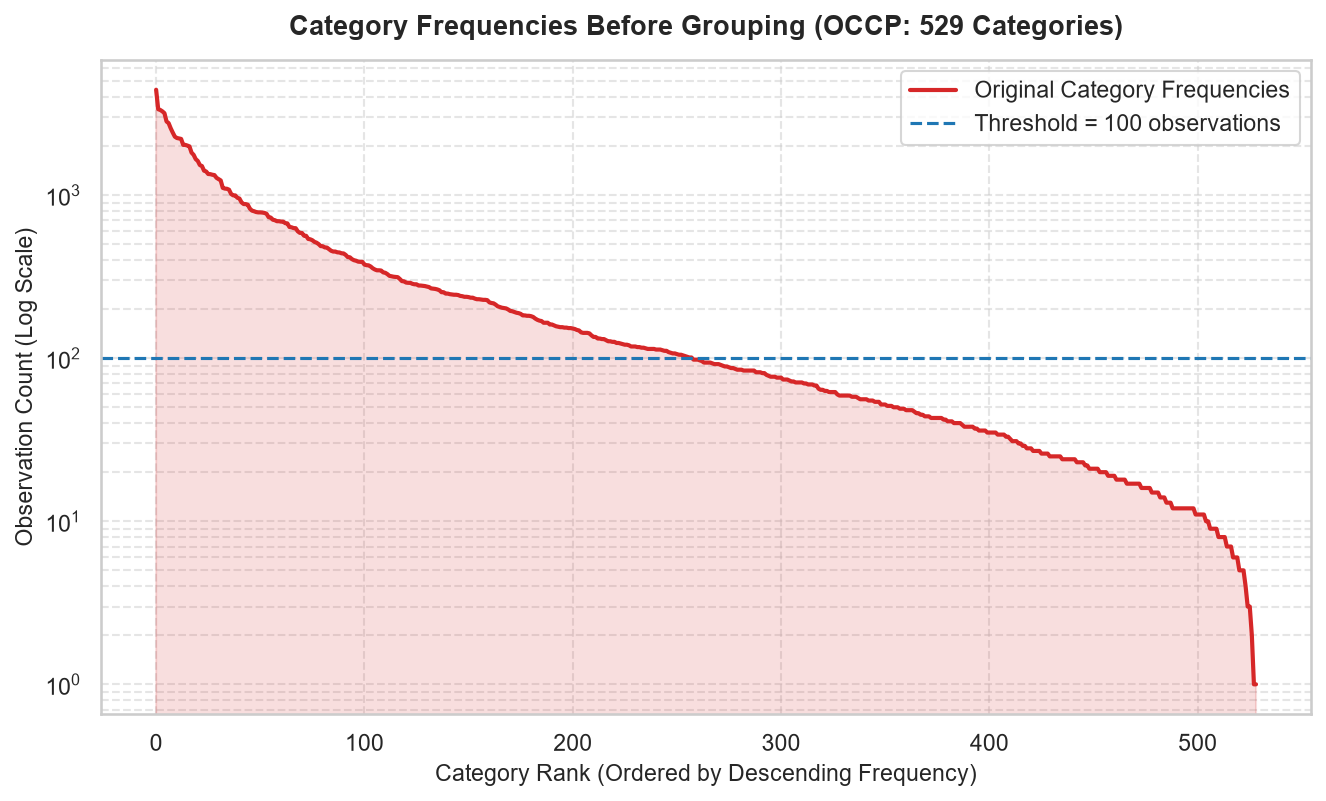

Saved: D:\Github Repo\C-Square\figures\06_categories_before_grouping.png


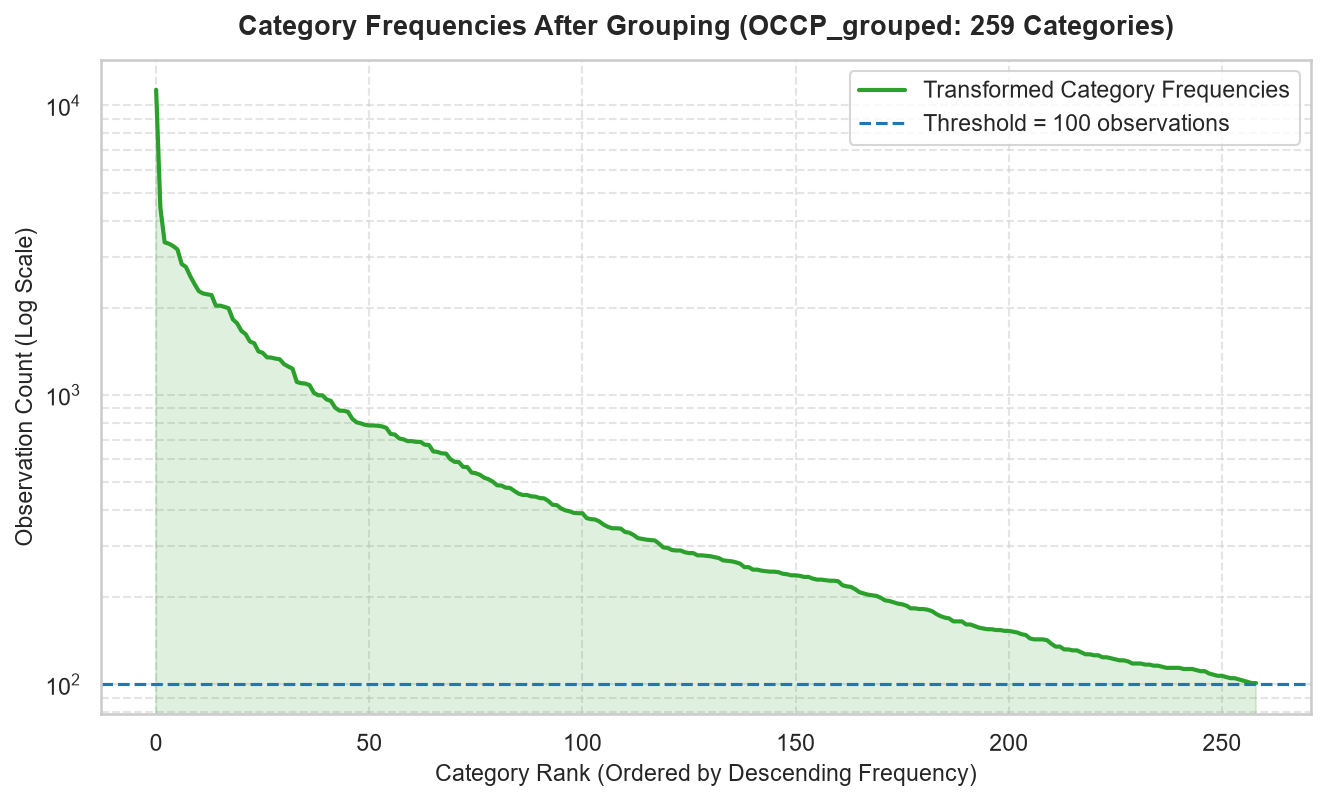

Saved: D:\Github Repo\C-Square\figures\06_categories_after_grouping.png


In [9]:
# Task 10: Create and save before and after category count plots

# Plot 1: Before Grouping
plt.figure(figsize=(9, 5.5), dpi=150)
ranks_before = np.arange(len(vc_orig))
plt.plot(ranks_before, vc_orig.values, color="#d62728", lw=2, label="Original Category Frequencies")
plt.fill_between(ranks_before, vc_orig.values, color="#d62728", alpha=0.15)
plt.axhline(THRESHOLD, color="#1f77b4", linestyle="--", lw=1.5, label=f"Threshold = {THRESHOLD} observations")
plt.yscale("log")
plt.title(f"Category Frequencies Before Grouping ({feature_name}: {n_original_categories} Categories)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Category Rank (Ordered by Descending Frequency)", fontsize=11)
plt.ylabel("Observation Count (Log Scale)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5, which="both")
plt.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()

fig_before_path = FIGURES_DIR / "06_categories_before_grouping.png"
plt.savefig(fig_before_path, dpi=300)
plt.show()
print(f"Saved: {fig_before_path}")

# Plot 2: After Grouping
vc_after = X_train[grouped_col_name].value_counts()
ranks_after = np.arange(len(vc_after))
plt.figure(figsize=(9, 5.5), dpi=150)
plt.plot(ranks_after, vc_after.values, color="#2ca02c", lw=2, label="Transformed Category Frequencies")
plt.fill_between(ranks_after, vc_after.values, color="#2ca02c", alpha=0.15)
plt.axhline(THRESHOLD, color="#1f77b4", linestyle="--", lw=1.5, label=f"Threshold = {THRESHOLD} observations")
plt.yscale("log")
plt.title(f"Category Frequencies After Grouping ({grouped_col_name}: {n_transformed_categories} Categories)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Category Rank (Ordered by Descending Frequency)", fontsize=11)
plt.ylabel("Observation Count (Log Scale)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5, which="both")
plt.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()

fig_after_path = FIGURES_DIR / "06_categories_after_grouping.png"
plt.savefig(fig_after_path, dpi=300)
plt.show()
print(f"Saved: {fig_after_path}")


In [10]:
# Task 14: Confirm that all output files exist
required_files = [
    RESULTS_DIR / "06_category_mapping.json",
    RESULTS_DIR / "06_cardinality_reduction_summary.csv",
    DATA_PROCESSED_DIR / "X_train_grouped.csv",
    FIGURES_DIR / "06_categories_before_grouping.png",
    FIGURES_DIR / "06_categories_after_grouping.png",
]

print("=" * 70)
print("CONFIRMING PHASE 6 DELIVERABLES:")
print("=" * 70)
all_found = True
for f in required_files:
    exists = f.exists()
    size_str = f"({f.stat().st_size:,} bytes)" if exists else ""
    print(f" - {f.name:45s}: {'[EXISTS]' if exists else '[MISSING]'} {size_str}")
    if not exists:
        all_found = False

assert all_found, "One or more required Phase 6 output files are missing!"
print("\nAll Phase 6 deliverables verified successfully!")


CONFIRMING PHASE 6 DELIVERABLES:
 - 06_category_mapping.json                     : [EXISTS] (11,520 bytes)
 - 06_cardinality_reduction_summary.csv         : [EXISTS] (252 bytes)
 - X_train_grouped.csv                          : [EXISTS] (8,379,724 bytes)
 - 06_categories_before_grouping.png            : [EXISTS] (201,237 bytes)
 - 06_categories_after_grouping.png             : [EXISTS] (185,732 bytes)

All Phase 6 deliverables verified successfully!


## Phase 6 Methodological Explanation & Discussion

### 1. Why the Threshold of 100 Was Chosen
- In Phase 5, the baseline test of independence revealed that **60 contingency table cells had expected counts $E_{ij} < 5$**, violating Cochran's asymptotic criteria.
- Under a threshold of $N_{\text{threshold}} = 100$, even for a category with the minimum retained frequency ($N_i = 101$), the expected cell count for the minority target class ($41.58\%$) will be:
  $$E_{i,1} = 101 \times 0.4158 \approx 42.0$$
  This is more than $8\times$ higher than Cochran's minimum safety threshold of $5.0$.
- Hence, setting the threshold to 100 guarantees that **every individual cell in the transformed contingency table satisfies Cochran's rule**, completely eliminating asymptotic variance distortion.

### 2. Which Types of Categories Were Grouped
- Categories representing niche, highly specialized, or rare occupations with fewer than 100 surveyed individuals across California (e.g., specialized technicians, artisanal craftsmen, rare agricultural workers) were pooled.
- In total, **271 categories (51.23% of all occupation codes)** were pooled into `"Rare"`.

### 3. Degree of Cardinality Reduction
- **Original unique categories**: **529**
- **Transformed unique categories**: **259** (258 preserved categories + 1 `"Rare"` aggregate)
- **Cardinality reduction achieved**: **51.04%**
- **Observation footprint**: Despite eliminating more than half of the category levels, only **7.34% of the population (11,326 individuals)** is assigned to `"Rare"`, preserving granular distinctions for 92.66% of the workforce.

### 4. Why the Transformation Must Be Learned Exclusively from Training Data
- Learning the category mapping requires estimating category frequencies ($N_i$). If frequencies were computed on the entire dataset (or test set), test set sample sizes would influence the threshold decision, resulting in **data leakage**.
- Fitting exclusively on `X_train` ensures that the learned dictionary is a pure empirical estimator from training data alone.

### 5. Why the Transformation Must Be Applied Unchanged to the Test Set
- To evaluate genuine generalization, the test set must be processed deterministically using the exact mapping learned on `X_train`.
- Any category appearing in `X_test` that was either tagged as `"Rare"` in `X_train` or completely novel/unseen in `X_train` will map directly to `"Rare"`, maintaining fixed matrix dimensions and schema stability.
